<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_inequality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial inequality of poverty and night-time lights

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

How unequal are Bolivia's municipalities, how much of that inequality is regional, and did it change as poverty fell? This notebook measures inequality in two indicators:

- **Multidimensional poverty** (`sdg1_2_mpi`, Multidimensional Poverty Index, 0–1; **higher = poorer**) of the *Atlas de los ODS en Bolivia 2026* (SDSN Bolivia), computed from the population censuses of 2012 and 2024, for all **343 municipalities and indigenous autonomies**, in **both periods**.
- **Night-time lights per capita** (`ln_t400NTLpc`, the Hodrick–Prescott trend of log lights per person) in 2012. Lights and the WorldPop population behind them cover only **333 units**: the 6 municipalities that lost territory to the new indigenous autonomies (Colquechaca, Mizque, Porco, Tomave, San Ignacio, Santa Ana) and the 4 new units have no data. Every result for lights is computed on those 333 units.

Outline:

1. **Load** the data with `geo4bolivia`
2. **Distributions** and maps
3. **Theil index**, decomposed between and within the 9 departments
4. **Gini coefficient**
5. **Spatial Gini**: how much inequality lies between neighbouring municipalities
6. **Summary**

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "inequality"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import geo4bolivia as geo
from libpysal import weights
import inequality
from inequality.gini import Gini_Spatial

import warnings
warnings.filterwarnings("ignore")

## 1. Load the data

Each municipality has one `geo_id` (e.g. `BO-04-17-04`, Nuestra Señora de La Paz). Poverty comes from the SDG Atlas, stored as the years 2012 and 2024; `wide=` gives one column per period. Census population (dataset `sdg`) serves as weights for poverty. Lights come from the `ntl` dataset in 2012, with the WorldPop population (`pop`) of the same year. `geometry=True` attaches the boundaries; `geo.units()` gives each municipality its department.

In [3]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", wide="sdg1_2_mpi")        # 343 units, 2012 and 2024
census = geo.load("sdg", variables="population")                           # census population, 2012 and 2024
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=2012)                # 333 units
pop = geo.load("pop", years=2012)                                          # WorldPop, 333 units

units = geo.units("municipality")
departments = geo.units("department").set_index("geo_id")["name"]

gdf = (geo.load("sdg01", variables="sdg1_2_mpi", years=2024, geometry=True)[["geo_id", "name", "geometry"]]
          .merge(mpi, on="geo_id")
          .merge(census.pivot(index="geo_id", columns="year", values="population").add_prefix("census_"),
                 on="geo_id")
          .merge(ntl[["geo_id", "ln_t400NTLpc"]], on="geo_id", how="left")     # NaN for the 10 units without lights
          .merge(pop[["geo_id", "pop"]], on="geo_id", how="left")
          .merge(units[["geo_id", "department_id"]], on="geo_id"))
gdf["department"] = gdf["department_id"].map(departments)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])     # metres, for maps and neighbours

print(gdf.shape, "| units without lights:", int(gdf["ln_t400NTLpc"].isna().sum()))
gdf[["geo_id", "name", "department", "sdg1_2_mpi2012", "sdg1_2_mpi2024", "ln_t400NTLpc", "census_2024"]].head()

(343, 11) | units without lights: 10


,geo_id,name,department,sdg1_2_mpi2012,sdg1_2_mpi2024,ln_t400NTLpc,census_2024
0,BO-01-01-01,Azurduy,Chuquisaca,0.512,0.187,11.048312,7903
1,BO-01-01-02,Tarvita,Chuquisaca,0.452,0.133,12.329279,16812
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.267,0.056,12.815315,9107
3,BO-01-03-01,Huacareta,Chuquisaca,0.346,0.071,12.018971,7200
4,BO-01-03-02,Monteagudo,Chuquisaca,0.212,0.043,14.603350,24546


In [4]:
MPI12, MPI24 = "sdg1_2_mpi2012", "sdg1_2_mpi2024"   # Multidimensional Poverty Index (higher = poorer)
NTL = "ln_t400NTLpc"                                # log night-time lights per capita, HP trend, 2012
GROUP = "department"                                # 9 departments
VARS = [MPI12, MPI24, NTL]
labels = {MPI12: "Multidimensional poverty index (2012)",
          MPI24: "Multidimensional poverty index (2024)",
          NTL: "Log night-time lights per capita (2012)"}

# each indicator on the units that have it: 343 for poverty, 333 for lights
data = {var: gdf[gdf[var].notna()].reset_index(drop=True) for var in VARS}
{labels[v]: len(d) for v, d in data.items()}

{'Multidimensional poverty index (2012)': 343,
 'Multidimensional poverty index (2024)': 343,
 'Log night-time lights per capita (2012)': 333}

## 2. Distributions and maps

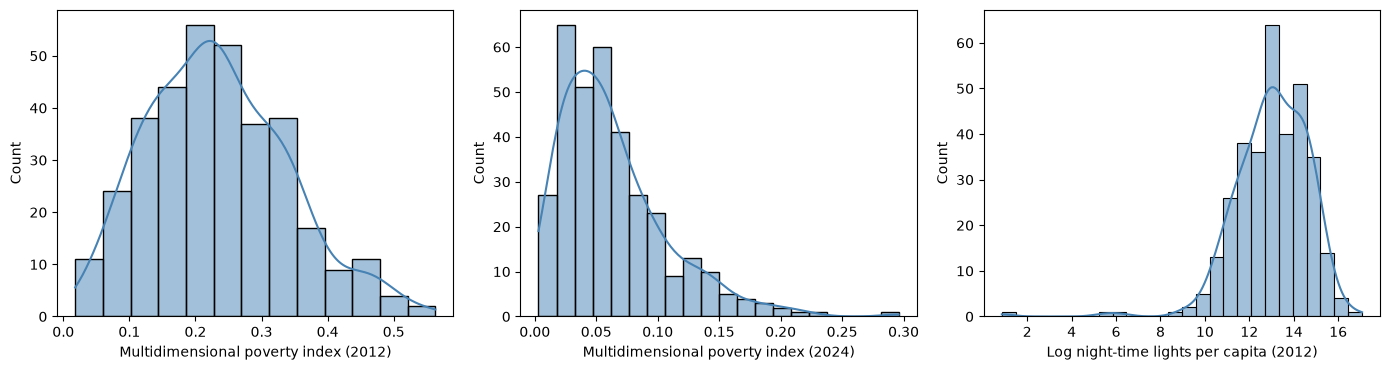

,sdg1_2_mpi2012,sdg1_2_mpi2024,ln_t400NTLpc
count,343.000,343.000,333.000
mean,0.234,0.063,13.030
std,0.106,0.044,1.682
min,0.018,0.003,0.856
25%,0.153,0.030,12.041
50%,0.227,0.053,13.118
75%,0.306,0.083,14.277
max,0.563,0.296,17.071


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, var in zip(axes, VARS):
    sns.histplot(data[var][var], kde=True, ax=ax, color="steelblue")
    ax.set_xlabel(labels[var])
plt.tight_layout()
plt.show()

gdf[VARS].describe().round(3)

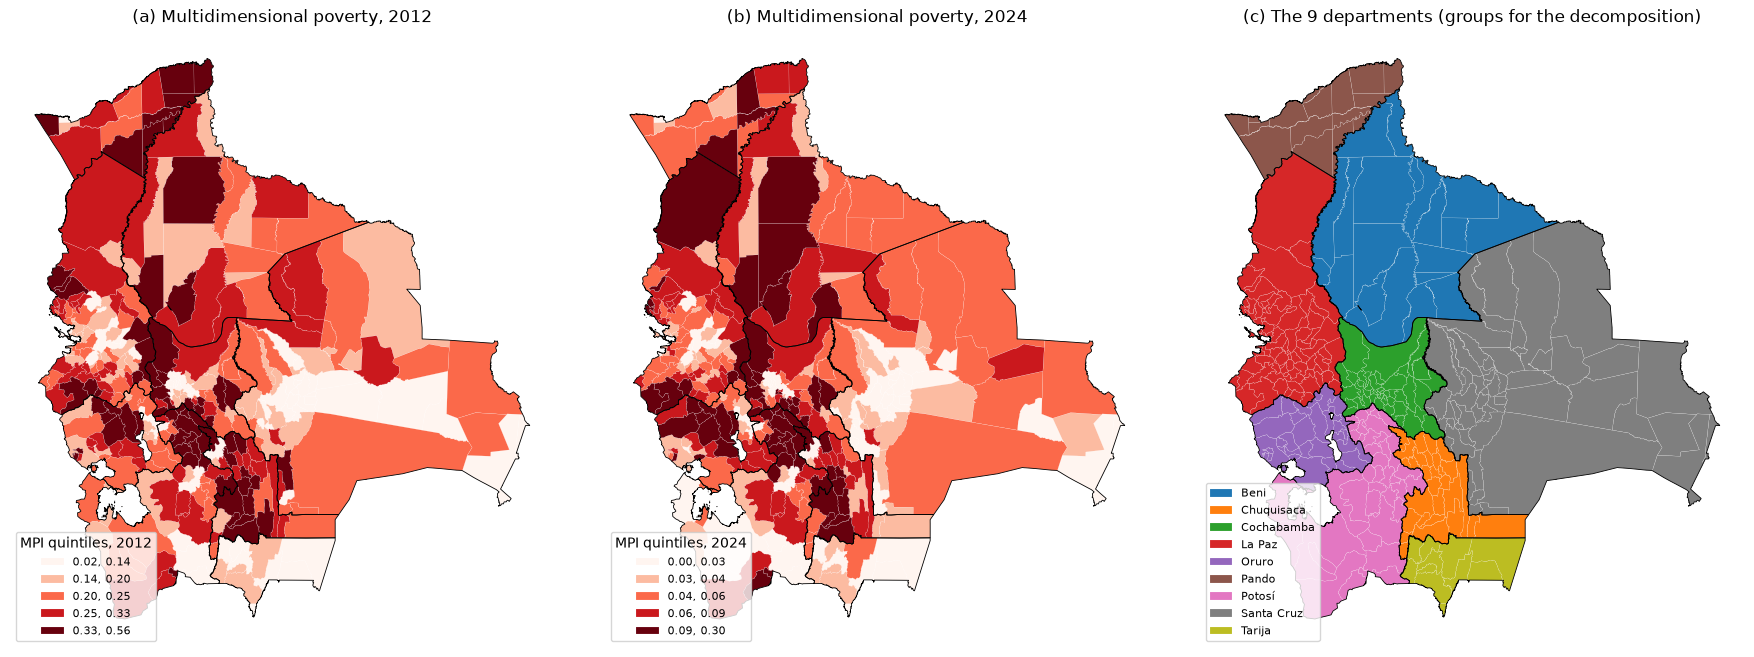

In [6]:
# department outlines
dep_lines = geo.boundaries("department").to_crs(gdf.crs).boundary

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, var, year in zip(axes, [MPI12, MPI24], [2012, 2024]):
    gdf.plot(column=var, scheme="Quantiles", k=5, cmap="Reds", linewidth=0.1, edgecolor="white",
             legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": f"MPI quintiles, {year}"}, ax=ax)
    ax.set_title(f"({'ab'[year == 2024]}) Multidimensional poverty, {year}")
gdf.plot(column=GROUP, categorical=True, cmap="tab10", linewidth=0.1, edgecolor="white",
         legend=True, legend_kwds={"loc": "lower left", "fontsize": 8}, ax=axes[2])
axes[2].set_title("(c) The 9 departments (groups for the decomposition)")
for ax in axes:
    dep_lines.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

Poverty fell sharply: the municipal mean MPI dropped from 0.234 in 2012 (range 0.018 to 0.563) to 0.063 in 2024 (range 0.003 to 0.296). Its absolute spread narrowed too (standard deviation 0.106, then 0.044), but less than the mean, so relative to the mean it widened, from 0.45 to 0.70 of the mean. In 2024 most municipalities bunch near zero with a long right tail. Each map uses its own quintiles. In both periods the poorest quintile lies mainly in the Andean valleys where northern Potosí, Chuquisaca and Cochabamba meet and in the Oruro highlands; in 2012 it also covers much of Pando. The least poor quintile holds the departmental capitals, much of Santa Cruz and Tarija. Log lights per capita (333 units) are concentrated around 13 (the middle half between 12.0 and 14.3), with a handful of very dark outliers (one below 1).

Before decomposing, the department averages show how large the regional gaps are. The population-weighted mean uses `geo.aggregate` with the census population of each period as weights; mean lights use the 333 units with data:

In [7]:
dep_pw = geo.aggregate(geo.load("sdg01", variables="sdg1_2_mpi"), to="department",
                       rules={"sdg1_2_mpi": "weighted_mean:population"}, weights=census)
dep_pw = dep_pw.pivot(index="geo_id", columns="year", values="sdg1_2_mpi").add_prefix("pop_weighted_mpi_")
dep_pw.index = dep_pw.index.map(departments)

dep_table = (gdf.groupby(GROUP)
               .agg(units=(MPI12, "size"), mean_mpi_2012=(MPI12, "mean"), mean_mpi_2024=(MPI24, "mean"),
                    units_with_lights=(NTL, "count"), mean_ln_ntl_2012=(NTL, "mean"))
               .join(dep_pw)
               .sort_values("mean_mpi_2024", ascending=False))
dep_table.round(3)

,units,mean_mpi_2012,mean_mpi_2024,units_with_lights,mean_ln_ntl_2012,pop_weighted_mpi_2012,pop_weighted_mpi_2024
department,,,,,,,
Chuquisaca,29,0.323,0.090,29,12.635,0.221,0.058
Potosí,42,0.279,0.083,37,12.406,0.224,0.063
Beni,20,0.250,0.075,17,12.001,0.229,0.072
Cochabamba,48,0.230,0.070,46,13.802,0.142,0.038
Oruro,35,0.235,0.069,35,13.209,0.129,0.037
Pando,15,0.315,0.068,15,12.471,0.236,0.049
La Paz,87,0.224,0.060,87,12.403,0.110,0.027
Santa Cruz,56,0.169,0.032,56,14.047,0.095,0.017
Tarija,11,0.118,0.027,11,14.509,0.079,0.018


In [8]:
nat = geo.aggregate(geo.load("sdg01", variables="sdg1_2_mpi"), to="country",
                    rules={"sdg1_2_mpi": "weighted_mean:population"}, weights=census)
print("Bolivia, population-weighted MPI:", dict(zip(nat["year"], nat["sdg1_2_mpi"].round(3))))
print("Bolivia, mean across municipalities:", gdf[[MPI12, MPI24]].mean().round(3).to_dict())

Bolivia, population-weighted MPI: {2012: 0.133, 2024: 0.033}
Bolivia, mean across municipalities: {'sdg1_2_mpi2012': 0.234, 'sdg1_2_mpi2024': 0.063}


Chuquisaca has the highest mean MPI in both periods (0.323, then 0.090) and Tarija the lowest (0.118, then 0.027). Pando had the largest drop: from the second poorest department on average in 2012 (0.315) to the sixth in 2024 (0.068). In every department and in both periods the population-weighted MPI is below the unweighted mean: the populous municipalities, led by the capitals, are less poor than the small rural ones. For the country, the population-weighted MPI is 0.133 in 2012 and 0.033 in 2024, against means across municipalities of 0.234 and 0.063.

## 3. Theil index

The Theil index is 0 under perfect equality and rises with inequality. Its key property is **additive decomposability**: with the municipalities grouped into departments, total inequality splits exactly into a *between-department* part (differences in department means) and a *within-department* part (differences among municipalities of the same department). Like the Gini below, it is a relative measure: multiplying every value by the same factor leaves it unchanged.

In [9]:
theil = {var: inequality.theil.Theil(data[var][var].values).T for var in VARS}
{labels[var]: round(float(t), 4) for var, t in theil.items()}

{'Multidimensional poverty index (2012)': 0.1039,
 'Multidimensional poverty index (2024)': 0.2192,
 'Log night-time lights per capita (2012)': 0.0096}

In [10]:
rows = []
for var in VARS:
    d = inequality.theil.TheilD(data[var][var].values, data[var][GROUP].values)
    total, between, within = float(theil[var]), float(np.squeeze(d.bg)), float(np.squeeze(d.wg))
    rows.append({"variable": var, "units": len(data[var]), "Theil": total, "between": between, "within": within,
                 "between share": between / total, "within share": within / total})
theil_table = pd.DataFrame(rows).set_index("variable")
theil_table.round(4)

,units,Theil,between,within,between share,within share
variable,,,,,,
sdg1_2_mpi2012,343,0.1039,0.0222,0.0817,0.2132,0.7868
sdg1_2_mpi2024,343,0.2192,0.0470,0.1722,0.2144,0.7856
ln_t400NTLpc,333,0.0096,0.0016,0.0079,0.1711,0.8289


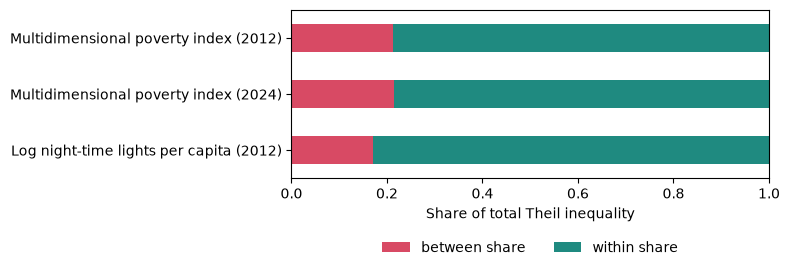

In [11]:
ax = theil_table[["between share", "within share"]].rename(index=labels).plot.barh(
    stacked=True, color=["#d84a64", "#1f8a80"], figsize=(8, 3))
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_xlabel("Share of total Theil inequality")
ax.set_ylabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

The Theil index of poverty **doubled**, from 0.104 in 2012 to 0.219 in 2024. Poverty fell everywhere, but proportionally less in the poorest municipalities, so the relative gaps between municipalities widened even as the absolute gaps narrowed. The Theil index of log lights (0.010, 333 units) is much smaller than that of poverty, but the two levels are not comparable: lights enter in logs, which compresses their dispersion by construction, while the MPI is a ratio-scale index. Only the **shares** of the decomposition are comparable.

For every indicator **most inequality is within departments**: 79% for poverty in both 2012 and 2024, and 83% for lights. Differences between department averages explain 21% of poverty inequality in both periods and 17% of lights inequality. The split is stable: inequality rose by the same proportion between and within departments. Bolivia's municipal disparities are therefore mostly local: each department contains both poor and less-poor municipalities.

## 4. Gini coefficient

The Gini coefficient (0 = equality, 1 = maximal inequality) is half the mean absolute difference between all pairs of municipalities, relative to the mean.

In [12]:
gini = {var: inequality.gini.Gini(data[var][var].values).g for var in VARS}
{labels[var]: round(float(g), 4) for var, g in gini.items()}

{'Multidimensional poverty index (2012)': 0.2535,
 'Multidimensional poverty index (2024)': 0.367,
 'Log night-time lights per capita (2012)': 0.0679}

The Gini of poverty rose from 0.254 in 2012 to 0.367 in 2024: the expected gap in MPI between two randomly drawn municipalities (twice the Gini) grew from about 51% to about 73% of the mean MPI. The Gini of log lights is 0.068, small for the same reason as its Theil index.

## 5. Spatial Gini

The spatial Gini (Rey and Smith, 2013) splits the Gini into the contribution of pairs of **neighbouring** municipalities and that of non-neighbours. If inequality had no spatial structure, neighbours would differ as much as any random pair, and their share of the Gini would roughly equal their share of all pairs. A smaller share means neighbours are more alike than random pairs (positive spatial autocorrelation). The p-value compares the observed split with 999 random reshufflings of the values across the map.

Neighbours are the 6 nearest municipalities (k-nearest neighbours on centroids in the equal-area projection), as in the original DS4Bolivia notebook. With k-nearest neighbours no unit is left without neighbours (no islands). The weights are built separately for each set of units: on all 343 for poverty, and on the 333 with lights for lights, so that every unit's 6 neighbours have data. `Gini_Spatial` only uses who is a neighbour, so the weights stay binary.

In [13]:
W = {}
for var in VARS:
    W[var] = weights.KNN.from_dataframe(data[var], k=6)    # binary: 1 for each of the 6 nearest neighbours
    print(f"{labels[var]}: {W[var].n} units, islands: {len(W[var].islands)}")

np.random.seed(12345)
rows = []
for var in VARS:
    n, w = len(data[var]), W[var]
    sg = Gini_Spatial(data[var][var].values, w, permutations=999)
    rows.append({"variable": var,
                 "units": n,
                 "Gini": sg.g,
                 "neighbour pairs, % of pairs": 100 * w.s0 / (n * (n - 1)),
                 "neighbour share of Gini, %": 100 * sg.wg / sg.dtotal,
                 "expected if random, %": 100 * (1 - sg.e_wcg / sg.dtotal),
                 "non-neighbour Gini (wcg_share)": sg.wcg_share,
                 "p-value": sg.p_sim})
spatial_gini = pd.DataFrame(rows).set_index("variable")
spatial_gini.round(4)

Multidimensional poverty index (2012): 343 units, islands: 0
Multidimensional poverty index (2024): 343 units, islands: 0
Log night-time lights per capita (2012): 333 units, islands: 0


,units,Gini,"neighbour pairs, % of pairs","neighbour share of Gini, %","expected if random, %",non-neighbour Gini (wcg_share),p-value
variable,,,,,,,
sdg1_2_mpi2012,343,0.2535,1.7544,1.2209,1.7553,0.2504,0.001
sdg1_2_mpi2024,343,0.3670,1.7544,1.2836,1.7548,0.3623,0.001
ln_t400NTLpc,333,0.0679,1.8072,1.3412,1.8066,0.0670,0.001


With 343 units, pairs of neighbours are 1.75% of all pairs of municipalities, and under random reshuffling they would carry about the same share of the Gini (1.75%). In fact they carry only 1.22% of poverty inequality in 2012 and 1.28% in 2024. For lights (333 units) neighbours are 1.81% of pairs and carry 1.34% of the Gini. The difference is significant for all three (p = 0.001, the smallest value 999 permutations allow): **inequality is spatially structured**. Neighbours resemble each other, and almost all inequality (about 98.7% of the Gini) comes from pairs of municipalities that are not neighbours. The neighbour share rose slightly from 2012 to 2024, so neighbours became a little less alike, in line with the lower Moran's I of 2024 in `esda`. The `wcg_share` column, which the original DS4Bolivia notebook printed, is this non-neighbour part in Gini units (for poverty 0.250 of 0.254 in 2012 and 0.362 of 0.367 in 2024), not a share of neighbours.

## 6. Summary

In [14]:
summary = pd.DataFrame({
    "Units": theil_table["units"],
    "Theil": theil_table["Theil"],
    "Theil: between departments": theil_table["between share"],
    "Theil: within departments": theil_table["within share"],
    "Gini": pd.Series({v: float(g) for v, g in gini.items()}),
    "Spatial Gini: neighbour share, %": spatial_gini["neighbour share of Gini, %"],
    "Spatial Gini: p-value": spatial_gini["p-value"],
}).rename(index=labels)
summary.T.round(4)

,Multidimensional poverty index (2012),Multidimensional poverty index (2024),Log night-time lights per capita (2012)
Units,343.0000,343.0000,333.0000
Theil,0.1039,0.2192,0.0096
Theil: between departments,0.2132,0.2144,0.1711
Theil: within departments,0.7868,0.7856,0.8289
Gini,0.2535,0.3670,0.0679
"Spatial Gini: neighbour share, %",1.2209,1.2836,1.3412
Spatial Gini: p-value,0.0010,0.0010,0.0010


- Municipal **poverty fell sharply but became more unequal in relative terms**: the Gini rose from 0.25 to 0.37 and the Theil index from 0.10 to 0.22 between 2012 and 2024, because the poorest municipalities reduced their poverty proportionally less. Lights (2012, 333 units), measured in logs, show low inequality on that scale.
- **Most inequality lies within departments**: 79% for poverty in both periods and 83% for lights. Departmental averages hide most of the disparities that matter for targeting.
- Inequality is **spatially structured** in both periods: neighbouring municipalities resemble each other, so the poor and the less-poor municipalities form regional clusters that cut across department boundaries.

Related notebooks: `esda` and `esda_dependence` (Moran's I and LISA clusters in both periods) and `esda_heterogeneity` (GWR and MGWR of poverty on lights).